# Домашнє завдання до теми 6
**Студентка:** Вох Ірина
**Дисципліна:** Вступ до машинного навчання (ІПЗ, 5 семестр)

**Мета:** перебудувати модель логістичної регресії з теми 5 на датасеті *Rain in Australia* так, щоб вона оцінювалась на даних з умовного «майбутнього»:
- рік спостереження обробляється як **числова** ознака, місяць — як **категоріальна**;
- до тестової вибірки потрапляють усі спостереження за **останній (максимальний) рік**, решта — у тренувальну;
- далі: відновлення пропусків (`SimpleImputer`), нормалізація (`StandardScaler`), кодування (`OneHotEncoder`), модель `LogisticRegression`, метрики через `classification_report()` і порівняння з базовою моделлю з теми 5.

## 1. Імпорт пакетів

In [1]:
import os
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             balanced_accuracy_score, classification_report,
                             f1_score)
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings('ignore')

## 2. Завантаження набору даних
Завантажую датасет так само, як у темі 5 (розділ «Практика застосування логістичної регресії. EDA датасету Rain in Australia»), — з файлу `../datasets/n03_01_weather_data.csv.gz`.

> Якщо файлу курсу немає поруч (наприклад, ноутбук запускають в іншій папці), код бере публічну копію того самого датасету Kaggle *weatherAUS* з GitHub. У старій версії цієї копії є зайва колонка `RISK_MM` (кількість опадів наступного дня — це фактично відповідь, витік цільової змінної), тому її видаляю, щоб набір ознак збігався з курсовим.

Первинний EDA цього датасету вже зроблено в темі 5, тому тут його не повторюю.

In [2]:
DATA_PATH = '../datasets/n03_01_weather_data.csv.gz'
BACKUP_URL = ('https://raw.githubusercontent.com/amankharwal/'
              'Website-data/master/weatherAUS.csv')

if os.path.exists(DATA_PATH):
    data = pd.read_csv(DATA_PATH)
else:
    data = pd.read_csv(BACKUP_URL).drop(columns='RISK_MM', errors='ignore')

print(data.shape)
data.head()

(142193, 23)


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


## 3. Підготовка даних і розбиття на вибірки

### 3.1. Видалення ознак з великою кількістю пропусків
Як і в темі 5, відкидаю колонки, у яких частка пропусків перевищує 0.35, а також рядки без цільової мітки `RainTomorrow`.

In [3]:
data.isna().mean().sort_values(ascending=False).head(6)

Sunshine       0.476929
Evaporation    0.427890
Cloud3pm       0.401525
Cloud9am       0.377353
Pressure9am    0.098556
Pressure3pm    0.098324
dtype: float64

In [4]:
data = data[data.columns[data.isna().mean().lt(0.35)]]
data = data.dropna(subset='RainTomorrow')

print('Видалено колонки з пропусками > 35%: Sunshine, Evaporation, Cloud3pm, Cloud9am')
print(data.shape)

Видалено колонки з пропусками > 35%: Sunshine, Evaporation, Cloud3pm, Cloud9am
(142193, 19)


### 3.2. Підмножини з числовими та категоріальними ознаками

In [5]:
data_num = data.select_dtypes(include=np.number)
data_cat = data.select_dtypes(exclude=np.number).copy()

print('Числові:', list(data_num.columns))
print('Категоріальні:', list(data_cat.columns))

Числові: ['MinTemp', 'MaxTemp', 'Rainfall', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Temp9am', 'Temp3pm']
Категоріальні: ['Date', 'Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday', 'RainTomorrow']


### 3.3. Колонка `Date` → `datetime`, нові колонки `Year` і `Month`
Місяць зберігаю як рядок, щоб далі він кодувався як категорія (сезонність), а не як число. Саму колонку `Date` після цього видаляю: кожна дата унікальна і як ознака не потрібна.

In [6]:
data_cat['Date'] = pd.to_datetime(data_cat['Date'])

data_cat['Year'] = data_cat['Date'].dt.year
data_cat['Month'] = data_cat['Date'].dt.month.astype(str)

data_cat = data_cat.drop('Date', axis=1)

data_cat[['Year', 'Month']].head()

,Year,Month
0,2008,12
1,2008,12
2,2008,12
3,2008,12
4,2008,12


### 3.4. Переміщення `Year` до числових ознак
Надалі рік обробляється як числова ознака, а місяць — як категоріальна.

In [7]:
data_num = pd.concat([data_num, data_cat.pop('Year')], axis=1)

print('Числові:', list(data_num.columns))
print('Категоріальні:', list(data_cat.columns))

Числові: ['MinTemp', 'MaxTemp', 'Rainfall', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Temp9am', 'Temp3pm', 'Year']
Категоріальні: ['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday', 'RainTomorrow', 'Month']


### 3.5. Розбиття на тренувальну і тестову вибірки за роками
У тестову вибірку відношу всі спостереження з останнього (максимального) року, у тренувальну — всі інші. Для цього використовую булеву індексацію `DataFrame`. Так модель під час навчання не бачить жодного дня з останнього року, і оцінка ближча до реального використання (прогноз на «майбутнє»).

In [8]:
last_year = data_num['Year'].max()
test_mask = data_num['Year'] == last_year

y = data_cat.pop('RainTomorrow')

X_train_num, X_test_num = data_num[~test_mask], data_num[test_mask]
X_train_cat, X_test_cat = data_cat[~test_mask], data_cat[test_mask]
y_train, y_test = y[~test_mask], y[test_mask]

print(f'Тестовий рік: {last_year}')
print(f'Роки в train: {X_train_num["Year"].min()}–{X_train_num["Year"].max()}')
print(f'Train: {len(y_train)} спостережень, test: {len(y_test)} спостережень')

Тестовий рік: 2017
Роки в train: 2007–2016
Train: 133727 спостережень, test: 8466 спостережень


## 4. Відновлення пропущених значень (`SimpleImputer`)
Імпутери навчаю **тільки на тренувальній вибірці**, а потім застосовую до обох вибірок — так немає витоку інформації з тестових даних. Для числових ознак — середнє, для категоріальних — мода.

In [9]:
num_imputer = SimpleImputer().set_output(transform='pandas')
X_train_num = num_imputer.fit_transform(X_train_num)
X_test_num = num_imputer.transform(X_test_num)

cat_imputer = SimpleImputer(strategy='most_frequent').set_output(transform='pandas')
X_train_cat = cat_imputer.fit_transform(X_train_cat)
X_test_cat = cat_imputer.transform(X_test_cat)

print('Пропусків у числових:', pd.concat([X_train_num, X_test_num]).isna().sum().sum())
print('Пропусків у категоріальних:', pd.concat([X_train_cat, X_test_cat]).isna().sum().sum())

Пропусків у числових: 0
Пропусків у категоріальних: 0


## 5. Нормалізація числових ознак (`StandardScaler`)

In [10]:
scaler = StandardScaler().set_output(transform='pandas')

X_train_num = scaler.fit_transform(X_train_num)
X_test_num = scaler.transform(X_test_num)

X_train_num.describe().loc[['mean', 'std']].round(2)

,MinTemp,MaxTemp,Rainfall,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Temp9am,Temp3pm,Year
mean,-0.0,0.0,0.0,-0.0,-0.0,0.0,-0.0,-0.0,0.0,0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## 6. Кодування категоріальних ознак (`OneHotEncoder`)
`drop='if_binary'` залишає одну колонку для бінарної ознаки `RainToday`. `handle_unknown='ignore'` — страховка на випадок, якщо в тестовому році трапиться категорія, якої не було в тренувальних даних.

In [11]:
encoder = (OneHotEncoder(drop='if_binary',
                         sparse_output=False,
                         handle_unknown='ignore')
           .set_output(transform='pandas'))

X_train_cat = encoder.fit_transform(X_train_cat)
X_test_cat = encoder.transform(X_test_cat)

X_train_cat.shape, X_test_cat.shape

((133727, 110), (8466, 110))

## 7. Об'єднання ознак і побудова моделі `LogisticRegression`

### 7.1. Об'єднання числових і закодованих категоріальних ознак

In [12]:
X_train = pd.concat([X_train_num, X_train_cat], axis=1)
X_test = pd.concat([X_test_num, X_test_cat], axis=1)

X_train.shape, X_test.shape

((133727, 123), (8466, 123))

### 7.2. Розподіл цільової змінної
Класи незбалансовані (дощових днів приблизно чверть), тому, як і в темі 5, використовую `class_weight='balanced'`.

In [13]:
y_train.value_counts(normalize=True).round(3)

RainTomorrow
No     0.775
Yes    0.225
Name: proportion, dtype: float64

### 7.3. Експерименти з гіперпараметром `solver`
Подібно до того, як у темі 6 задавали додаткові параметри навчання дерева, порівнюю різні алгоритми оптимізації (`solver`) логістичної регресії. Усі інші параметри однакові: `class_weight='balanced'`, `random_state=42`, `max_iter=1000`. Для довідки додаю також варіант без балансування класів.

In [14]:
solvers = ['liblinear', 'lbfgs', 'newton-cg', 'newton-cholesky', 'sag', 'saga']
experiments = [(s, 'balanced') for s in solvers] + [('liblinear', None)]

results = []
for solver, class_weight in experiments:
    start = time.time()
    model = LogisticRegression(solver=solver,
                               class_weight=class_weight,
                               max_iter=1000,
                               random_state=42).fit(X_train, y_train)
    pred = model.predict(X_test)
    results.append({
        'solver': solver,
        'class_weight': class_weight or 'None',
        'accuracy': accuracy_score(y_test, pred),
        'balanced_accuracy': balanced_accuracy_score(y_test, pred),
        'f1 (Yes)': f1_score(y_test, pred, pos_label='Yes'),
        'час, с': time.time() - start,
    })

pd.DataFrame(results).round(3)

,solver,class_weight,accuracy,balanced_accuracy,f1 (Yes),"час, с"
0,liblinear,balanced,0.798,0.769,0.598,1.077
1,lbfgs,balanced,0.798,0.769,0.597,2.513
2,newton-cg,balanced,0.798,0.769,0.598,1.771
3,newton-cholesky,balanced,0.798,0.769,0.598,3.148
4,sag,balanced,0.798,0.769,0.598,5.262
5,saga,balanced,0.798,0.769,0.598,12.799
6,liblinear,None,0.847,0.698,0.547,1.056


Висновок з експериментів: усі солвери з `class_weight='balanced'` сходяться практично до одного й того самого рішення (accuracy ≈ 0.80, різниця лише в третьому знаку), бо задача опукла і всі вони знаходять той самий мінімум. Відрізняються вони переважно швидкістю: `liblinear` і `newton-cholesky` найшвидші, `saga` — найповільніший. Без балансування класів accuracy вища (≈ 0.85), але це ефект дисбалансу: модель частіше прогнозує «сухий» день, recall дощових днів сильно падає, і balanced accuracy (≈ 0.70 проти ≈ 0.77) та f1 для класу `Yes` (≈ 0.55 проти ≈ 0.60) стають гіршими. Тобто модель частіше «пропускає» дощ. Тому для фінальної моделі залишаю `liblinear` з `class_weight='balanced'` — так само, як у базовій моделі теми 5, щоб порівняння було коректним.

### 7.4. Фінальна модель

In [15]:
clf = (LogisticRegression(solver='liblinear',
                          class_weight='balanced',
                          random_state=42)
       .fit(X_train, y_train))

y_pred = clf.predict(X_test)

## 8. Метрики нової моделі та порівняння з базовою

In [16]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          No       0.92      0.82      0.87      6703
         Yes       0.51      0.72      0.60      1763

    accuracy                           0.80      8466
   macro avg       0.71      0.77      0.73      8466
weighted avg       0.83      0.80      0.81      8466



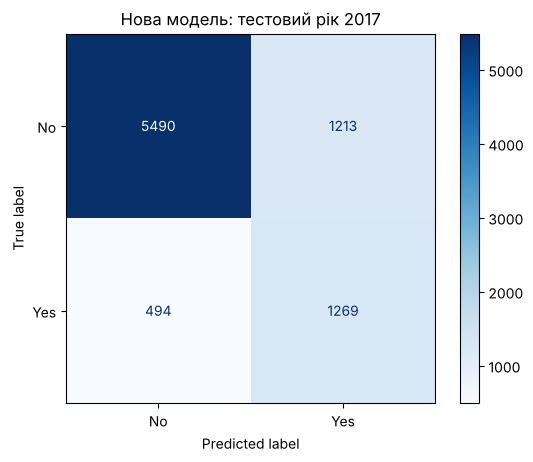

In [17]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap='Blues')
plt.title(f'Нова модель: тестовий рік {last_year}')
plt.show()

### Порівняння з базовою моделлю з теми 5
Метрики базової моделі взято з розділу «Практика застосування логістичної регресії. Навчання й оцінка моделі. Оцінювання точності моделі» теми 5 (випадкове розбиття `train_test_split`, `test_size=0.2`, рік і місяць як категорії).

In [18]:
report = classification_report(y_test, y_pred, output_dict=True)

comparison = pd.DataFrame({
    'Базова модель (тема 5)': {
        'precision (Yes)': 0.51, 'recall (Yes)': 0.76, 'f1 (Yes)': 0.61,
        'precision (No)': 0.92, 'recall (No)': 0.79, 'f1 (No)': 0.85,
        'accuracy': 0.79,
    },
    'Нова модель (тест = останній рік)': {
        'precision (Yes)': report['Yes']['precision'],
        'recall (Yes)': report['Yes']['recall'],
        'f1 (Yes)': report['Yes']['f1-score'],
        'precision (No)': report['No']['precision'],
        'recall (No)': report['No']['recall'],
        'f1 (No)': report['No']['f1-score'],
        'accuracy': report['accuracy'],
    },
})

print('Розмір тестової вибірки: базова модель — 28439, нова модель —', len(y_test))
comparison.round(2)

Розмір тестової вибірки: базова модель — 28439, нова модель — 8466


,Базова модель (тема 5),Нова модель (тест = останній рік)
precision (Yes),0.51,0.51
recall (Yes),0.76,0.72
f1 (Yes),0.61,0.60
precision (No),0.92,0.92
recall (No),0.79,0.82
f1 (No),0.85,0.87
accuracy,0.79,0.80


## Висновки

1. **Обробка часових ознак.** З колонки `Date` створено `Year` і `Month`. Рік перенесено до числових ознак, тож модель може вловити загальний тренд, а не запам'ятовувати окремі роки як категорії (у темі 5 рік кодувався one-hot, і для нового року в моделі просто не було б колонки). Місяць лишився категорією і відповідає за сезонність.
2. **Розбиття.** До тестової вибірки потрапили всі 8466 спостережень за останній рік (2017; у даних він неповний, січень–червень), до тренувальної — усі попередні роки. Модель не бачила жодного дня з тестового року, тому оцінка чесніша, ніж при випадковому розбитті в темі 5, де дні того самого року й тієї самої станції опинялися і в train, і в test.
3. **Preprocessing.** `SimpleImputer`, `StandardScaler` і `OneHotEncoder` навчено тільки на тренувальній вибірці й лише застосовано до тестової, тож витоку даних немає.
4. **Метрики.** Нова модель має accuracy ≈ **0.80**, що відповідає очікуваному результату із завдання (support: No — 6703, Yes — 1763). Для класу `No`: precision 0.92, recall 0.82, f1 0.87. Для класу `Yes`: precision 0.51, recall 0.72, f1 0.60.
5. **Порівняння з базовою моделлю.** Метрики дуже близькі: accuracy 0.80 проти 0.79, precision дощу однакова (0.51), f1 для «дощу» 0.60 проти 0.61. Recall дощових днів трохи нижчий (0.72 проти 0.76), а recall сухих днів трохи вищий (0.82 проти 0.79): на «майбутньому» році модель стала трохи обережнішою з прогнозом дощу. Головне: якість **не впала** при переході до суворішої, реалістичної схеми оцінювання. Отже, модель справді узагальнює закономірності на нові періоди, а не лише «впізнає» вже бачені дні.
6. **Solver.** Вибір `solver` майже не впливає на якість (усі варіанти ≈ 0.80 accuracy), бо логістична регресія — опукла задача; він впливає лише на швидкість навчання. Балансування класів (`class_weight='balanced'`) важливіше: без нього accuracy формально вища (≈ 0.85), але модель пропускає значно більше дощових днів (balanced accuracy падає з ≈ 0.77 до ≈ 0.70).
7. **Практичний зміст.** Якщо брати парасольку щоразу, коли модель прогнозує дощ, ми будемо готові приблизно до 72% дощових днів, але приблизно половина прогнозів дощу буде хибною (precision 0.51). Для простої лінійної моделі на щоденних погодних показниках це прийнятна базова якість. Покращити її можна складнішими моделями (дерева рішень, ансамблі) або ознаками з попередніх днів.